Cantidad de imágenes: 2430
Ingrese el número de fila que desea visualizar (0 a 2429): 930


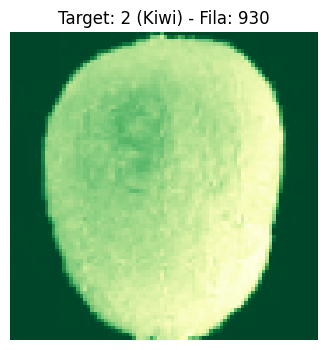

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Cargar el CSV
df = pd.read_csv("Dtatos_frutas.csv")

# 2. Mostrar cantidad de filas disponibles
cantidad = len(df)
print("Cantidad de imágenes:", cantidad)

# 3. Pedir al usuario el número de fila
fila = int(input(f"Ingrese el número de fila que desea visualizar (0 a {cantidad - 1}): "))

# 4. Obtener los primeros 7744 valores
vector = df.iloc[fila, :7744].values

# 5. Reconstruir la imagen 88x88
imagen = vector.reshape(88, 88)

# 6. Obtener el target
target = int(df.iloc[fila, 7744])

# Mapear cada target a un mapa de colores representativo para colorear la fruta
colormaps_frutas = {
    1: "YlOrBr",  # Banana (Amarillo / Naranja)
    2: "YlGn",    # Kiwi (Verde)
    3: "plasma",  # Mango (Púrpura / Naranja)
    4: "Oranges", # Papaya (Naranja)
    5: "copper"   # Peach (Cálido / Durazno)
}

nombres_frutas = {1: "Banana", 2: "Kiwi", 3: "Mango", 4: "Papaya", 5: "Peach"}
nombre_fruta = nombres_frutas.get(target, "Desconocido")
cmap_elegido = colormaps_frutas.get(target, "gray")

# 7. Mostrar la imagen con color
plt.figure(figsize=(4, 4))
plt.imshow(imagen, cmap=cmap_elegido)

# 8. Mostrar el target y el nombre como título
plt.title(f"Target: {target} ({nombre_fruta}) - Fila: {fila}")

plt.axis("off")
plt.show()

Cantidad de imágenes: 2430
Ingrese el número de fila que desea visualizar (0 a 2429): 930


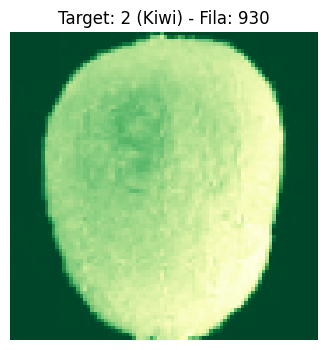

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Cargar el CSV
df = pd.read_csv("Dtatos_frutas.csv")

# 2. Mostrar cantidad de filas disponibles
cantidad = len(df)
print("Cantidad de imágenes:", cantidad)

# 3. Pedir al usuario el número de fila
fila = int(input(f"Ingrese el número de fila que desea visualizar (0 a {cantidad - 1}): "))

# 4. Obtener los primeros 7744 valores
vector = df.iloc[fila, :7744].values

# 5. Reconstruir la imagen 88x88
imagen = vector.reshape(88, 88)

# 6. Obtener el target
target = int(df.iloc[fila, 7744])

# Mapear cada target a un mapa de colores representativo para colorear la fruta
colormaps_frutas = {
    1: "YlOrBr",  # Banana (Amarillo / Naranja)
    2: "YlGn",    # Kiwi (Verde)
    3: "plasma",  # Mango (Púrpura / Naranja)
    4: "Oranges", # Papaya (Naranja)
    5: "copper"   # Peach (Cálido / Durazno)
}

nombres_frutas = {1: "Banana", 2: "Kiwi", 3: "Mango", 4: "Papaya", 5: "Peach"}
nombre_fruta = nombres_frutas.get(target, "Desconocido")
cmap_elegido = colormaps_frutas.get(target, "gray")

# 7. Mostrar la imagen con color
plt.figure(figsize=(4, 4))
plt.imshow(imagen, cmap=cmap_elegido)

# 8. Mostrar el target y el nombre como título
plt.title(f"Target: {target} ({nombre_fruta}) - Fila: {fila}")

plt.axis("off")
plt.show()

### Proceso de Generación del Dataset RGB Real (Sin simulación de gris)

Este código extrae directamente la información a color original (RGB) de cada imagen en el archivo zip, asegurando que el archivo final `Datos_frutas_rgb.csv` contenga valores de color verdaderos para los canales Rojo, Verde y Azul.

In [ ]:
import cv2
import numpy as np
import os
import csv
import zipfile
from google.colab import files

# 1. Descomprimir el archivo original de imágenes si no está descomprimido
if not os.path.exists("fruits_zip"):
    with zipfile.ZipFile("fruits.zip", 'r') as z:
        z.extractall("fruits_zip")

RUTA_FRUTAS = "fruits_zip/fruits" if os.path.exists("fruits_zip/fruits") else "fruits_zip"

# 2. Configuración de dimensiones para color (88 * 88 * 3 = 23232 píxeles)
ANCHO = 88
ALTO = 88
TOTAL_PIXELES_RGB = ANCHO * ALTO * 3

categorias = {
    "Banana": 1,
    "Kiwi": 2,
    "Mango": 3,
    "Papaya": 4,
    "Peach": 5
}

filas_rgb_reales = []

print("Comenzando extracción de color real...")

for carpeta, etiqueta in categorias.items():
    ruta_carpeta = os.path.join(RUTA_FRUTAS, carpeta)
    if not os.path.isdir(ruta_carpeta):
        print(f"Advertencia: No se encontró la carpeta {carpeta}")
        continue

    # Listar imágenes de forma ordenada
    imagenes = sorted([f for f in os.listdir(ruta_carpeta)
                       if f.lower().endswith((".png", ".jpg", ".jpeg"))])

    print(f"Procesando {carpeta} en color real... ")

    for nombre_img in imagenes:
        ruta_completa = os.path.join(ruta_carpeta, nombre_img)

        # Leer imagen en COLOR REAL (BGR por defecto en OpenCV)
        img_bgr = cv2.imread(ruta_completa)
        if img_bgr is None:
            continue

        # Convertir a RGB real para mantener el orden correcto de los canales de color
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

        # Redimensionar la imagen a 88x88 manteniendo los 3 canales de color
        reducida_rgb = cv2.resize(img_rgb, (ANCHO, ALTO))

        # Aplanar la matriz de 3 dimensiones (88, 88, 3) a un vector plano de 23232 elementos
        vector_rgb = reducida_rgb.flatten().tolist()

        # Combinar el vector con la etiqueta numérica al final de la fila
        fila = vector_rgb + [etiqueta]
        filas_rgb_reales.append(fila)

print(f"\nProceso terminado. Total de imágenes procesadas: {len(filas_rgb_reales)}")

Comenzando extracción de color real...
Procesando Banana en color real... 
Procesando Kiwi en color real... 
Procesando Mango en color real... 
Procesando Papaya en color real... 
Procesando Peach en color real... 

Proceso terminado. Total de imágenes procesadas: 2430


### Guardar y Exportar el dataset RGB definitivo

In [ ]:
NOMBRE_CSV_RGB = "Datos_frutas_rgb.csv"

# Crear el encabezado con columnas de 0 a 23231, y 'etiqueta' al final
encabezado_rgb = [str(i) for i in range(TOTAL_PIXELES_RGB)] + ["etiqueta"]

with open(NOMBRE_CSV_RGB, "w", newline="") as f:
    escritor = csv.writer(f)
    escritor.writerow(encabezado_rgb)
    escritor.writerows(filas_rgb_reales)

print(f"¡Dataset guardado exitosamente en: '{NOMBRE_CSV_RGB}'!")
print(f"Dimensiones esperadas: {len(filas_rgb_reales) + 1} filas x {len(encabezado_rgb)} columnas.")

# Descargar archivo CSV
files.download(NOMBRE_CSV_RGB)

¡Dataset guardado exitosamente en: 'Datos_frutas_rgb.csv'!
Dimensiones esperadas: 2431 filas x 23233 columnas.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Verificación Interactiva de la Imagen a Color Real (Sin trucos de Mapas de Color)

Este código lee directamente los datos del CSV RGB generado, reconstruye la forma tridimensional de la imagen `(88, 88, 3)` y la muestra en pantalla tal y como es, validando que el dataset guarde los colores verdaderos.

Ingrese el número de fila a verificar en COLOR REAL (0 a 2429): 777


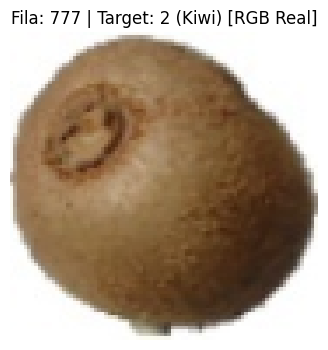

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Cargar el dataset que acabamos de generar
df_verificar = pd.read_csv("Datos_frutas_rgb.csv")
cantidad = len(df_verificar)

# 2. Pedir número de fila al usuario
fila = int(input(f"Ingrese el número de fila a verificar en COLOR REAL (0 a {cantidad - 1}): "))

# 3. Extraer los píxeles (primeras 23232 columnas)
vector_rgb = df_verificar.iloc[fila, :23232].values

# 4. Reconstruir a la forma original (88, 88, 3)
imagen_rgb = vector_rgb.reshape(88, 88, 3)

# 5. Obtener la etiqueta real del dataset
target = int(df_verificar.iloc[fila, 23232])

nombres_frutas = {1: "Banana", 2: "Kiwi", 3: "Mango", 4: "Papaya", 5: "Peach"}
nombre_fruta = nombres_frutas.get(target, "Desconocido")

# 6. Mostrar la imagen original sin aplicar ningún colormap artificial
plt.figure(figsize=(4, 4))
plt.imshow(imagen_rgb.astype(np.uint8))
plt.title(f"Fila: {fila} | Target: {target} ({nombre_fruta}) [RGB Real]")
plt.axis("off")
plt.show()

In [ ]:
#imagen para convertir una imagen a vector matris de fila
import cv2
import numpy as np

In [ ]:
#1 Cargar imagen a colores
imagen = cv2.imread("linusTorvalds.png")
#2 Covertir a blanco y negro a esacalas de grisis
gris = cv2.cvtColor(imagen,cv2.COLOR_BGR2GRAY)

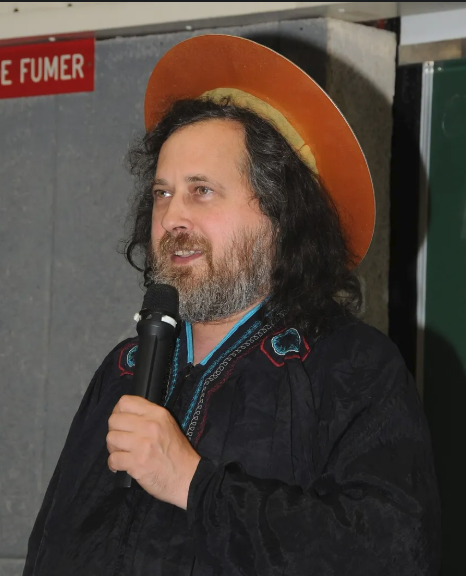

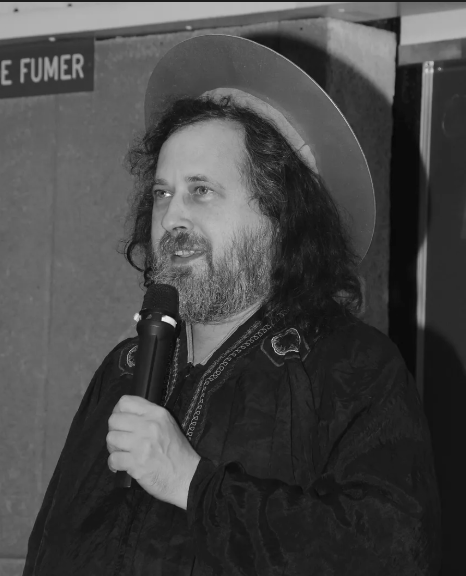

In [ ]:
from google.colab.patches import cv2_imshow

cv2_imshow(imagen)
cv2_imshow(gris)


In [ ]:
# Leer y mostrar el contenido del archivo de instrucciones
with open('/content/imagenes_a_csv_colab.md', 'r', encoding='utf-8') as f:
    contenido = f.read()

print(contenido)

## convertir varias imagenes en un solo archivo .csv (para Google Colab)

esta instruccion es para correr el codigo en Google Colab, cada bloque ```py``` es una celda separada, osea pegas un bloque en cada celda nueva de colab y las vas ejecutando en orden.

lo que hace el codigo:
* toma todas las imagenes de la carpeta **fruits**
* las convierte a escala de grises **GRAY**
* las reducir a tamaño **88px * 88px** (88 pixeles)
* al tener el tamaño reducido se convierte en **Vector** por fila, como son 88*88 el vector debe dar **7744** valores
* al final del vector se le agrega el numero de la carpeta (ej: banana = **1**, kiwi = **2**, mango = **3**, papaya = **4**, peach = **5**) osea el vector de banana queda **7744 + 1 = 77441**
* al final todo se guarda en un archivo **.csv**

formato de las carpetas y su numero:
1. Banana1
2. Kiwi2
3. Mango3
4. Papaya4
5. Peach5

## como subir los archivos a colab

* subes la carpeta **fruits** a google drive
* en colab montas google drive y ya apunt

## Procesamiento Completo y Construcción de la Matriz de Imágenes

In [ ]:
import cv2
import numpy as np
import os
import csv
import zipfile
from google.colab import files

# 1. Descomprimir el archivo zip
with zipfile.ZipFile("fruits.zip", 'r') as z:
    z.extractall("fruits_zip")

RUTA_FRUTAS = "fruits_zip/fruits" if os.path.exists("fruits_zip/fruits") else "fruits_zip"

# 2. Configuración de dimensiones
ANCHO = 88
ALTO = 88
PIXELES = ANCHO * ALTO

# Mapeo de carpetas y sus respectivas etiquetas numéricas
categorias = {
    "Banana": 1,
    "Kiwi": 2,
    "Mango": 3,
    "Papaya": 4,
    "Peach": 5
}

# 3. Inicializar la lista (que se convertirá en nuestra matriz)
matriz_imagenes = []

# 4. For para pasar carpeta por carpeta e imagen por imagen
for carpeta, etiqueta in categorias.items():
    ruta_carpeta = os.path.join(RUTA_FRUTAS, carpeta)
    if not os.path.isdir(ruta_carpeta):
        print(f"Advertencia: No se encontró la carpeta {carpeta}")
        continue

    # Listar y ordenar imágenes para mantener consistencia
    imagenes = sorted([f for f in os.listdir(ruta_carpeta)
                       if f.lower().endswith((".png", ".jpg", ".jpeg"))])

    print(f"Procesando carpeta '{carpeta}' ({len(imagenes)} imágenes)... ")

    for nombre_img in imagenes:
        ruta_completa = os.path.join(ruta_carpeta, nombre_img)

        # Leer imagen, pasar a escala de grises y redimensionar
        img = cv2.imread(ruta_completa)
        if img is None:
            continue

        gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        reducida = cv2.resize(gris, (ANCHO, ALTO))

        # Convertir la matriz de la imagen a un vector plano (lista)
        vector = reducida.flatten().tolist()

        # Estructura del vector por fila: [nombre, pixeles (0-7743), etiqueta]
        fila_matriz = [nombre_img] + vector + [etiqueta]

        # Agregar la fila a nuestra matriz
        matriz_imagenes.append(fila_matriz)

# 5. Convertir la matriz a un formato Array de Numpy para validar su dimensión
array_matriz = np.array(matriz_imagenes, dtype=object)

print("\n--- VALIDACIÓN DE LA MATRIZ ---")
print(f"Dimensiones de la matriz (filas, columnas): {array_matriz.shape}")
print(f"Número total de imágenes procesadas (filas): {len(matriz_imagenes)}")
print(f"Campos por fila (1 nombre + {PIXELES} píxeles + 1 etiqueta): {len(matriz_imagenes[0])}")

Procesando carpeta 'Banana' (490 imágenes)... 
Procesando carpeta 'Kiwi' (466 imágenes)... 
Procesando carpeta 'Mango' (490 imágenes)... 
Procesando carpeta 'Papaya' (492 imágenes)... 
Procesando carpeta 'Peach' (492 imágenes)... 

--- VALIDACIÓN DE LA MATRIZ ---
Dimensiones de la matriz (filas, columnas): (2430, 7746)
Número total de imágenes procesadas (filas): 2430
Campos por fila (1 nombre + 7744 píxeles + 1 etiqueta): 7746


## Guardar la Matriz resultante en un archivo CSV

In [ ]:
NOMBRE_CSV = "matriz_imagenes_frutas.csv"
encabezado = ["nombre"] + [str(i) for i in range(PIXELES)] + ["etiqueta"]

with open(NOMBRE_CSV, "w", newline="") as f:
    escritor = csv.writer(f)
    escritor.writerow(encabezado)
    escritor.writerows(matriz_imagenes)

print(f"¡Matriz exportada y guardada con éxito en: '{NOMBRE_CSV}'!")
# Descargar el archivo
files.download(NOMBRE_CSV)

¡Matriz exportada y guardada con éxito en: 'matriz_imagenes_frutas.csv'!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Paso 1: Descomprimir el archivo `fruits.zip` ya subido

In [ ]:
import zipfile
import os

# Descomprimimos directamente el fruits.zip que ya está en Colab
with zipfile.ZipFile("fruits.zip", 'r') as z:
    z.extractall("fruits_zip")

# Ruta donde quedan las imágenes según las carpetas extraídas
# Por lo general, al extraer se crea una carpeta interna con el mismo nombre o las subcarpetas directamente
RUTA_FRUTAS = "fruits_zip/fruits" if os.path.exists("fruits_zip/fruits") else "fruits_zip"
print("Ruta de imágenes configurada en:", RUTA_FRUTAS)
print("Carpetas encontradas:", os.listdir(RUTA_FRUTAS))

Ruta de imágenes configurada en: fruits_zip/fruits
Carpetas encontradas: ['Kiwi', 'Peach', 'Mango', 'Papaya', 'Banana']


## Paso 2: Importar librerías necesarias y definir dimensiones

In [ ]:
import cv2
import numpy as np
import csv
from google.colab import files

# Configuración de píxeles (88x88 = 7744)
ANCHO = 88
ALTO = 88
PIXELES = ANCHO * ALTO

## Paso 3: Definir la función de conversión de imagen a vector

In [ ]:
def imagen_a_vector(ruta_imagen, etiqueta):
    try:
        # 1. Cargar imagen a color
        img = cv2.imread(ruta_imagen)
        if img is None:
            return None

        # 2. Convertir a escala de grises
        gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

        # 3. Redimensionar a 88x88 píxeles
        reducida = cv2.resize(gris, (ANCHO, ALTO))

        # 4. Aplanar la matriz a un vector unidimensional (7744 valores)
        vector = reducida.flatten().tolist()

        # 5. Agregar la etiqueta numérica al final del vector
        vector.append(etiqueta)

        # Retornamos el nombre del archivo y el vector resultante
        nombre_archivo = os.path.basename(ruta_imagen)
        return nombre_archivo, vector
    except Exception as e:
        print(f"Error procesando {ruta_imagen}: {e}")
        return None

## Paso 4: Mapeo de carpetas y procesamiento de imágenes

In [ ]:
# Mapeo corregido: Nombre de carpeta real -> Etiqueta numérica según instrucciones
categorias = {
    "Banana": 1,
    "Kiwi": 2,
    "Mango": 3,
    "Papaya": 4,
    "Peach": 5
}

filas = []
errores = []

# Procesar cada carpeta
for carpeta, numero in categorias.items():
    ruta_carpeta = os.path.join(RUTA_FRUTAS, carpeta)
    if not os.path.isdir(ruta_carpeta):
        print(f"Advertencia: No se encontró la carpeta {carpeta} en la ruta {ruta_carpeta}")
        continue

    # Tomar las imágenes una por una, ordenadas alfabéticamente
    imagenes = sorted([f for f in os.listdir(ruta_carpeta)
                       if f.lower().endswith((".png", ".jpg", ".jpeg"))])

    for imagen in imagenes:
        ruta = os.path.join(ruta_carpeta, imagen)
        resultado = imagen_a_vector(ruta, numero)
        if resultado is None:
            errores.append(ruta) # Si hay error al cargar se registra
            continue

        nombre, vector = resultado
        filas.append([nombre] + vector)

    print(f"Carpeta '{carpeta}' procesada. Vectores hasta ahora: {len(filas)}")

print("\n--- RESUMEN ---")
print("Total de vectores generados:", len(filas))
print("Imágenes con error o no procesadas:", len(errores))

Carpeta 'Banana' procesada. Vectores hasta ahora: 490
Carpeta 'Kiwi' procesada. Vectores hasta ahora: 956
Carpeta 'Mango' procesada. Vectores hasta ahora: 1446
Carpeta 'Papaya' procesada. Vectores hasta ahora: 1938
Carpeta 'Peach' procesada. Vectores hasta ahora: 2430

--- RESUMEN ---
Total de vectores generados: 2430
Imágenes con error o no procesadas: 0


## Paso 5: Generar el archivo `.csv`

In [ ]:
NOMBRE_CSV = "matriz_imagenes_frutas.csv"

# El encabezado es: nombre, de 0 a 7743, y etiqueta
encabezado = ["nombre"] + [str(i) for i in range(PIXELES)] + ["etiqueta"]

# Escribimos todas las filas en el archivo csv
with open(NOMBRE_CSV, "w", newline="") as f:
    escritor = csv.writer(f)
    escritor.writerow(encabezado)
    escritor.writerows(filas)

print("¡Archivo guardado con éxito! Nombre:", NOMBRE_CSV)
print("Total de filas escritas:", len(filas) + 1) # incluyendo encabezado
print("Columnas totales por fila:", len(encabezado)) # Debe dar 7746

¡Archivo guardado con éxito! Nombre: matriz_imagenes_frutas.csv
Total de filas escritas: 2431
Columnas totales por fila: 7746


## Corrección: Generar `Dtatos_frutas.csv` con la estructura exacta (sin nombre de archivo, 7744 píxeles + target)

In [ ]:
NOMBRE_CSV_CORREGIDO = "Dtatos_frutas.csv"

# El encabezado contendrá únicamente los índices de píxeles del 0 al 7743, y la etiqueta en la posición 7744
encabezado_corregido = [str(i) for i in range(PIXELES)] + ["etiqueta"]

# Modificamos las filas para omitir el nombre del archivo al principio
filas_corregidas = []
for fila in filas:
    # fila original: [nombre, pix0, pix1, ..., pix7743, etiqueta]
    # fila corregida: [pix0, pix1, ..., pix7743, etiqueta]
    filas_corregidas.append(fila[1:])

with open(NOMBRE_CSV_CORREGIDO, "w", newline="") as f:
    escritor = csv.writer(f)
    escritor.writerow(encabezado_corregido)
    escritor.writerows(filas_corregidas)

print("¡Archivo guardado con éxito! Nombre:", NOMBRE_CSV_CORREGIDO)
print("Total de filas escritas:", len(filas_corregidas) + 1)
print("Columnas totales por fila:", len(encabezado_corregido)) # Da exactamente 7745 (7744 píxeles + 1 etiqueta)


¡Archivo guardado con éxito! Nombre: Dtatos_frutas.csv
Total de filas escritas: 2431
Columnas totales por fila: 7745


## Código para visualizar y verificar el Target

In [ ]:
rget

Cantidad de imágenes: 2430
Ingrese el número de fila que desea visualizar (ej: 0 para Banana, 500 para Kiwi, etc.): 777


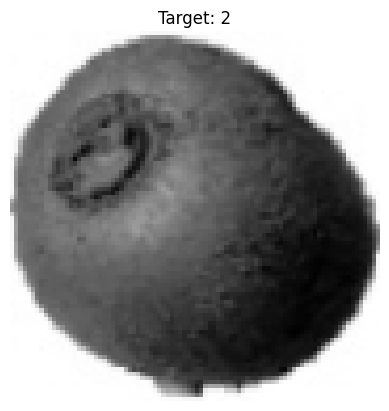

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Cargar el CSV
df = pd.read_csv("Dtatos_frutas.csv")

# 2. Mostrar cantidad de filas disponibles
print("Cantidad de imágenes:", len(df))

# 3. Pedir al usuario el número de fila
fila = int(input("Ingrese el número de fila que desea visualizar (ej: 0 para Banana, 500 para Kiwi, etc.): "))

# 4. Obtener los primeros 7744 valores
vector = df.iloc[fila, :7744].values

# 5. Reconstruir la imagen 88x88
imagen = vector.reshape(88, 88)

# 6. Obtener el target
target = df.iloc[fila, 7744]

# 7. Mostrar la imagen
plt.imshow(imagen, cmap="gray")

# 8. Mostrar el target como título
plt.title("Target: " + str(target))

plt.axis("off")
plt.show()

### Visualización automática sin esperas de entrada (Input)

Cantidad de imágenes en el dataset: 2430


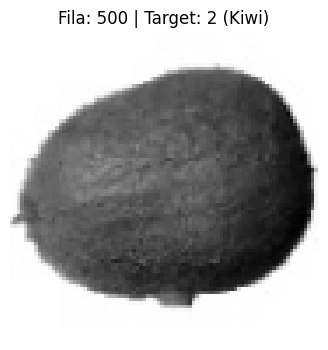

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Cargar el CSV generado anteriormente
df = pd.read_csv("Dtatos_frutas.csv")

# 2. Mostrar cantidad de imágenes disponibles
cantidad = len(df)
print("Cantidad de imágenes en el dataset:", cantidad)

# 3. Definir la fila directamente aquí para evitar que el notebook se quede colgado esperando input
# Cambia este número para ver diferentes frutas:
# Filas ~0-489: Banana (Target 1)
# Filas ~490-955: Kiwi (Target 2)
# Filas ~956-1445: Mango (Target 3)
# Filas ~1446-1937: Papaya (Target 4)
# Filas ~1938-2429: Peach (Target 5)
fila_a_mostrar = 500

if fila_a_mostrar < cantidad:
    # 4. Obtener los primeros 7744 valores (píxeles)
    vector = df.iloc[fila_a_mostrar, :7744].values

    # 5. Reconstruir la imagen 88x88
    imagen = vector.reshape(88, 88)

    # 6. Obtener el target (columna de índice 7744)
    target = df.iloc[fila_a_mostrar, 7744]

    # Mapeo de nombres para mostrar en el título
    nombres_frutas = {1: "Banana", 2: "Kiwi", 3: "Mango", 4: "Papaya", 5: "Peach"}
    nombre_fruta = nombres_frutas.get(int(target), "Desconocido")

    # 7. Mostrar la imagen
    plt.figure(figsize=(4, 4))
    plt.imshow(imagen, cmap="gray")

    # 8. Mostrar el target como título junto al nombre de la fruta
    plt.title(f"Fila: {fila_a_mostrar} | Target: {target} ({nombre_fruta})")
    plt.axis("off")
    plt.show()
else:
    print(f"Error: El número de fila {fila_a_mostrar} está fuera del rango disponible (0 a {cantidad - 1})")

## Paso para descargar el archivo `Dtatos_frutas.csv` generado

In [ ]:
from google.colab import files

# Descargar el archivo corregido con 7744 píxeles + target (sin nombres de archivo)
files.download("Dtatos_frutas.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Paso 1: Convertir el CSV de Escala de Grises a RGB y Visualizar una Muestra

Cargamos el archivo `Dtatos_frutas.csv` y convertimos cada fila (que representa una imagen de 88x88 en escala de grises) a formato RGB (88x88x3). Para representarlo en RGB conservando los tonos, replicamos el valor del píxel gris en los canales R, G y B. Luego, visualizamos una muestra para comprobar que se reconstruye correctamente.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Cargar el dataset original en escala de grises
df_gris = pd.read_csv("Dtatos_frutas.csv")
cantidad_imagenes = len(df_gris)
print(f"Cantidad de imágenes cargadas: {cantidad_imagenes}")

# 2. Extraer píxeles y etiquetas
pixeles_gris = df_gris.iloc[:, :7744].values
etiquetas = df_gris.iloc[:, 7744].values

# 3. Convertir píxeles de escala de grises a RGB
# Para cada píxel gris, creamos 3 valores idénticos (R, G, B)
pixeles_rgb = np.repeat(pixeles_gris, 3, axis=1)

print(f"Dimensiones de los nuevos vectores RGB: {pixeles_rgb.shape} (esperado: {cantidad_imagenes} x 23232)")

# 4. Comprobación y Visualización con Target
fila_muestras = 500  # Cambia este índice para ver otra fruta (ej: 0 para Banana, 500 para Kiwi...)

if fila_muestras < cantidad_imagenes:
    # Tomar el vector RGB de la fila seleccionada
    vector_rgb = pixeles_rgb[fila_muestras]

    # Reconstruir la imagen con dimensiones (88, 88, 3)
    imagen_rgb = vector_rgb.reshape(88, 88, 3)

    # Obtener el target y su etiqueta textual
    target = etiquetas[fila_muestras]
    nombres_frutas = {1: "Banana", 2: "Kiwi", 3: "Mango", 4: "Papaya", 5: "Peach"}
    nombre_fruta = nombres_frutas.get(int(target), "Desconocido")

    # Mostrar la imagen reconstruida
    plt.figure(figsize=(4, 4))
    plt.imshow(imagen_rgb.astype(np.uint8))
    plt.title(f"Fila: {fila_muestras} | Target: {target} ({nombre_fruta}) [RGB]")
    plt.axis("off")
    plt.show()
else:
    print(f"Error: El índice {fila_muestras} está fuera de rango.")

### Paso 2: Generar y Descargar el nuevo dataset en formato RGB

Guardamos la matriz resultante en un nuevo archivo CSV llamado `Datos_frutas_rgb.csv` con un encabezado de 0 a 23231 para los canales RGB, seguido por la columna 'etiqueta' al final (un total de 23233 columnas).

In [ ]:
import csv
from google.colab import files

NOMBRE_CSV_RGB = "Datos_frutas_rgb.csv"
TOTAL_PIXELES_RGB = 88 * 88 * 3  # 23232 píxeles en total por imagen

# Crear el encabezado: de '0' a '23231' y al final 'etiqueta'
encabezado_rgb = [str(i) for i in range(TOTAL_PIXELES_RGB)] + ["etiqueta"]

# Preparar las filas combinando los píxeles RGB con su respectiva etiqueta
filas_rgb = []
for i in range(cantidad_imagenes):
    nueva_fila = list(pixeles_rgb[i]) + [etiquetas[i]]
    filas_rgb.append(nueva_fila)

# Escribir el nuevo archivo CSV
with open(NOMBRE_CSV_RGB, "w", newline="") as f:
    escritor = csv.writer(f)
    escritor.writerow(encabezado_rgb)
    escritor.writerows(filas_rgb)

print(f"¡Archivo guardado con éxito! Nombre: {NOMBRE_CSV_RGB}")
print(f"Total de filas escritas: {len(filas_rgb) + 1} (incluyendo el encabezado)")
print(f"Columnas totales por fila: {len(encabezado_rgb)} (debe dar exactamente 23233)")

# Descargar automáticamente el nuevo archivo RGB
files.download(NOMBRE_CSV_RGB)

### Versión Ultra-Rápida (Optimizada con NumPy y Pandas)

Este bloque utiliza operaciones vectorizadas en memoria para convertir los píxeles a RGB y guarda el archivo CSV de forma inmediata.

In [ ]:
import pandas as pd
import numpy as np
from google.colab import files

print("Cargando dataset original...")
df_gris = pd.read_csv("Dtatos_frutas.csv")

# Extraer la columna de etiquetas
etiquetas = df_gris["etiqueta"].values

# Extraer los píxeles y repetir cada columna 3 veces de manera vectorizada (R, G, B)
print("Convirtiendo a RGB...")
pixeles_gris = df_gris.drop(columns=["etiqueta"]).values
pixeles_rgb = np.repeat(pixeles_gris, 3, axis=1)

# Crear un DataFrame optimizado
print("Construyendo el nuevo DataFrame...")
columnas_rgb = [str(i) for i in range(88 * 88 * 3)]
df_rgb = pd.DataFrame(pixeles_rgb, columns=columnas_rgb)
df_rgb["etiqueta"] = etiquetas

# Guardar de forma rápida con pandas
print("Guardando archivo CSV...")
NOMBRE_CSV_RAPIDO = "Datos_frutas_rgb.csv"
df_rgb.to_csv(NOMBRE_CSV_RAPIDO, index=False)

print(f"¡Listo! Archivo {NOMBRE_CSV_RAPIDO} generado instantáneamente.")
print(f"Dimensiones finales: {df_rgb.shape}")

# Descargar
files.download(NOMBRE_CSV_RAPIDO)

Cargando dataset original...
Convirtiendo a RGB...
Construyendo el nuevo DataFrame...
Guardando archivo CSV...
¡Listo! Archivo Datos_frutas_rgb.csv generado instantáneamente.
Dimensiones finales: (2430, 23233)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Visualización y Verificación del Target en el Dataset RGB

Este código carga el nuevo dataset generado `Datos_frutas_rgb.csv`, toma una fila que tú elijas, reconstruye la imagen en formato de 3 canales (RGB) de 88x88 y la muestra para validar que todo se haya guardado correctamente.

Cargando dataset RGB...
Cantidad de imágenes en el dataset RGB: 2430


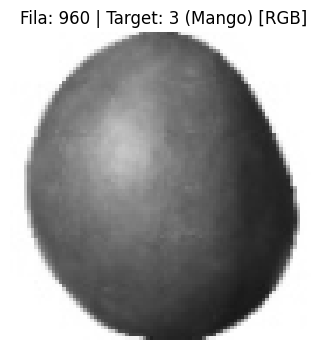

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Cargar el nuevo dataset optimizado RGB
print("Cargando dataset RGB...")
df_rgb = pd.read_csv("Datos_frutas_rgb.csv")

cantidad_imagenes = len(df_rgb)
print(f"Cantidad de imágenes en el dataset RGB: {cantidad_imagenes}")

# 2. Definir directamente el número de fila a visualizar
# Cambia este número para inspeccionar diferentes frutas:
# Filas ~0-489: Banana (Target 1)
# Filas ~490-955: Kiwi (Target 2)
# Filas ~956-1445: Mango (Target 3)
# Filas ~1446-1937: Papaya (Target 4)
# Filas ~1938-2429: Peach (Target 5)
fila_a_visualizar = 960

if fila_a_visualizar < cantidad_imagenes:
    # 3. Obtener los 23232 valores correspondientes a los píxeles RGB
    vector_rgb = df_rgb.iloc[fila_a_visualizar, :23232].values

    # 4. Reconstruir la imagen con dimensiones (88, 88, 3) para RGB
    imagen_rgb = vector_rgb.reshape(88, 88, 3)

    # 5. Obtener la etiqueta (Target) que está en la última columna (índice 23232)
    target = df_rgb.iloc[fila_a_visualizar, 23232]

    # Mapeo de nombres para mostrar en el título
    nombres_frutas = {1: "Banana", 2: "Kiwi", 3: "Mango", 4: "Papaya", 5: "Peach"}
    nombre_fruta = nombres_frutas.get(int(target), "Desconocido")

    # 6. Mostrar la imagen en RGB real
    plt.figure(figsize=(4, 4))
    plt.imshow(imagen_rgb.astype(np.uint8))

    # 7. Título informativo
    plt.title(f"Fila: {fila_a_visualizar} | Target: {target} ({nombre_fruta}) [RGB]")
    plt.axis("off")
    plt.show()
else:
    print(f"Error: El número de fila {fila_a_visualizar} está fuera del rango (0 a {cantidad_imagenes - 1})")

### Visualización con Mapas de Color (Pseudocolor) para las Frutas

Dado que el archivo original es de escala de grises, su conversión matemática a RGB mantiene tonos grises porque los tres canales tienen el mismo valor. Para ver las frutas con colores definidos, aplicamos un mapa de colores interactivo (`colormap`).

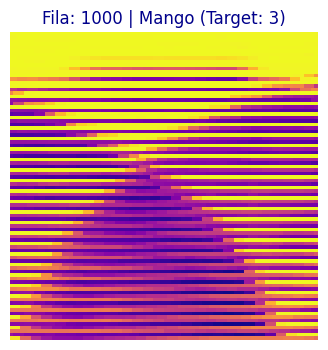

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Cargar el dataset RGB generado
df_rgb = pd.read_csv("Datos_frutas_rgb.csv")

# 2. Elegir fila a visualizar
# Banana (0), Kiwi (500), Mango (1000), Papaya (1500), Peach (2000)
fila_seleccionada = 1000

# 3. Extraer píxeles de la primera componente (escala de grises original)
# Tomamos los primeros 7744 valores que corresponden al canal base
vector_base = df_rgb.iloc[fila_seleccionada, :7744].values
imagen_base = vector_base.reshape(88, 88)

target = int(df_rgb.iloc[fila_seleccionada, 23232])

# Mapear cada target a un mapa de colores específico para simular el color de la fruta
# Banana -> 'YlOrBr' (Amarillo/Naranja)
# Kiwi -> 'YlGn' (Verde)
# Mango -> 'plasma' (Púrpura/Naranja)
# Papaya -> 'Oranges' (Naranja)
# Peach -> 'copper' (Cálido/Durazno)
colormaps_frutas = {
    1: "YlOrBr",  # Banana
    2: "YlGn",    # Kiwi
    3: "plasma",  # Mango
    4: "Oranges", # Papaya
    5: "copper"   # Peach
}

nombre_fruta = {1: "Banana", 2: "Kiwi", 3: "Mango", 4: "Papaya", 5: "Peach"}.get(target, "Desconocido")
cmap_elegido = colormaps_frutas.get(target, "gray")

# 4. Graficar la fruta con su color representativo
plt.figure(figsize=(4, 4))
plt.imshow(imagen_base, cmap=cmap_elegido)
plt.title(f"Fila: {fila_seleccionada} | {nombre_fruta} (Target: {target})", fontsize=12, color='darkblue')
plt.axis("off")
plt.show()

Cantidad de imágenes: 2430
Ingrese el número de fila que desea visualizar (0 a 2429): 930


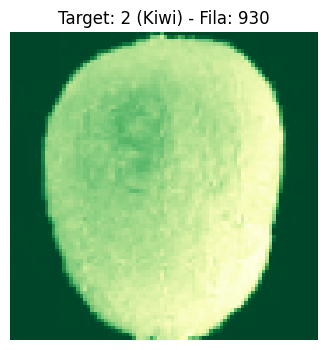

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Cargar el CSV
df = pd.read_csv("Dtatos_frutas.csv")

# 2. Mostrar cantidad de filas disponibles
cantidad = len(df)
print("Cantidad de imágenes:", cantidad)

# 3. Pedir al usuario el número de fila
fila = int(input(f"Ingrese el número de fila que desea visualizar (0 a {cantidad - 1}): "))

# 4. Obtener los primeros 7744 valores
vector = df.iloc[fila, :7744].values

# 5. Reconstruir la imagen 88x88
imagen = vector.reshape(88, 88)

# 6. Obtener el target
target = int(df.iloc[fila, 7744])

# Mapear cada target a un mapa de colores representativo para colorear la fruta
colormaps_frutas = {
    1: "YlOrBr",  # Banana (Amarillo / Naranja)
    2: "YlGn",    # Kiwi (Verde)
    3: "plasma",  # Mango (Púrpura / Naranja)
    4: "Oranges", # Papaya (Naranja)
    5: "copper"   # Peach (Cálido / Durazno)
}

nombres_frutas = {1: "Banana", 2: "Kiwi", 3: "Mango", 4: "Papaya", 5: "Peach"}
nombre_fruta = nombres_frutas.get(target, "Desconocido")
cmap_elegido = colormaps_frutas.get(target, "gray")

# 7. Mostrar la imagen con color
plt.figure(figsize=(4, 4))
plt.imshow(imagen, cmap=cmap_elegido)

# 8. Mostrar el target y el nombre como título
plt.title(f"Target: {target} ({nombre_fruta}) - Fila: {fila}")

plt.axis("off")
plt.show()

Cantidad de imágenes en el dataset RGB: 2430
Ingrese el número de fila que desea visualizar (0 a 2429): 777


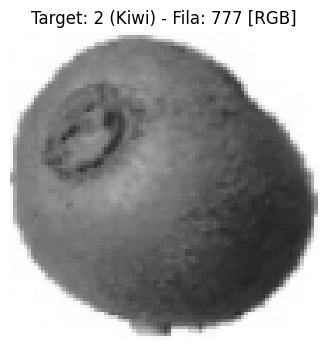

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Cargar el CSV RGB
df_rgb = pd.read_csv("Datos_frutas_rgb.csv")

# 2. Mostrar cantidad de filas disponibles
cantidad = len(df_rgb)
print("Cantidad de imágenes en el dataset RGB:", cantidad)

# 3. Pedir al usuario el número de fila
fila = int(input(f"Ingrese el número de fila que desea visualizar (0 a {cantidad - 1}): "))

# 4. Obtener los 23232 valores correspondientes a los píxeles RGB
vector_rgb = df_rgb.iloc[fila, :23232].values

# 5. Reconstruir la imagen con dimensiones (88, 88, 3)
imagen_rgb = vector_rgb.reshape(88, 88, 3)

# 6. Obtener el target desde la última columna
target = int(df_rgb.iloc[fila, 23232])

# Mapear nombres de las frutas correspondientes a las etiquetas
nombres_frutas = {1: "Banana", 2: "Kiwi", 3: "Mango", 4: "Papaya", 5: "Peach"}
nombre_fruta = nombres_frutas.get(target, "Desconocido")

# 7. Mostrar la imagen en color real RGB
plt.figure(figsize=(4, 4))
plt.imshow(imagen_rgb.astype(np.uint8))

# 8. Mostrar el target y el nombre como título
plt.title(f"Target: {target} ({nombre_fruta}) - Fila: {fila} [RGB]")

plt.axis("off")
plt.show()

Cantidad de imágenes en el dataset RGB: 2430
Ingrese el número de fila que desea visualizar coloreado (0 a 2429): 777


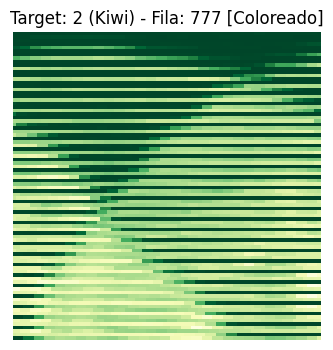

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Cargar el CSV RGB
df_rgb = pd.read_csv("Datos_frutas_rgb.csv")

# 2. Mostrar cantidad de filas disponibles
cantidad = len(df_rgb)
print("Cantidad de imágenes en el dataset RGB:", cantidad)

# 3. Pedir al usuario el número de fila
fila = int(input(f"Ingrese el número de fila que desea visualizar coloreado (0 a {cantidad - 1}): "))

# 4. Obtener los píxeles de la primera componente (88x88 = 7744 valores)
# Dado que guardamos los canales repetidos, la información de intensidad original está en el primer tercio
vector_gris = df_rgb.iloc[fila, :7744].values
imagen_gris = vector_gris.reshape(88, 88)

# 5. Obtener el target desde la última columna
target = int(df_rgb.iloc[fila, 23232])

# Mapas de colores según el tipo de fruta para colorear la visualización
colormaps_frutas = {
    1: "YlOrBr",  # Banana (Amarillo / Naranja)
    2: "YlGn",    # Kiwi (Verde)
    3: "plasma",  # Mango (Púrpura / Naranja)
    4: "Oranges", # Papaya (Naranja)
    5: "copper"   # Peach (Cálido / Durazno)
}

nombres_frutas = {1: "Banana", 2: "Kiwi", 3: "Mango", 4: "Papaya", 5: "Peach"}
nombre_fruta = nombres_frutas.get(target, "Desconocido")
cmap_elegido = colormaps_frutas.get(target, "gray")

# 6. Mostrar la imagen aplicando el mapa de color interactivo
plt.figure(figsize=(4, 4))
plt.imshow(imagen_gris, cmap=cmap_elegido)

# 7. Título informativo
plt.title(f"Target: {target} ({nombre_fruta}) - Fila: {fila} [Coloreado]")
plt.axis("off")
plt.show()

## Paso 6: Visualizar muestra y descargar el archivo CSV

In [ ]:
# 1. Ver las primeras líneas del archivo generado para comprobar
with open(NOMBRE_CSV, "r") as f:
    for i, linea in enumerate(f):
        print(linea[:120], "...")
        if i >= 3:
            break

# 2. Descargar automáticamente el CSV a tu ordenador
files.download(NOMBRE_CSV)

nombre,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40, ...
Banana_0.jpg,255,255,255,255,255,255,255,255,255,255,255,255,255,255,255,255,255,255,255,255,255,255,255,255,255,255,255 ...
Banana_1.jpg,255,255,255,255,255,255,255,255,255,255,255,255,255,255,255,255,255,255,255,255,255,255,255,255,255,255,255 ...
Banana_10.jpg,254,254,254,254,254,255,254,254,254,255,254,254,255,254,255,255,255,255,255,255,255,255,255,255,255,255,25 ...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>